In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression, HuberRegressor, RANSACRegressor
from sklearn.metrics import mean_squared_error

In [ ]:
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
df = sns.load_dataset('tips')
print(df.info())
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


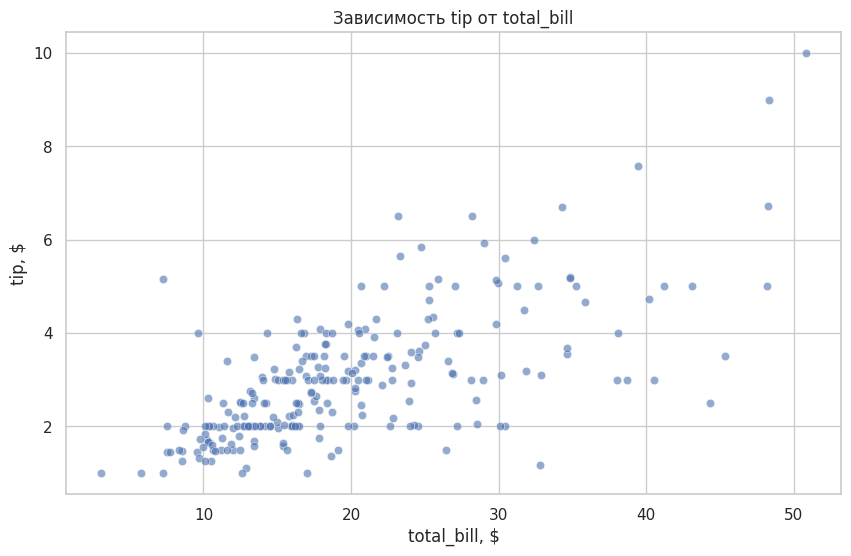

In [ ]:
plt.figure()
sns.scatterplot(data=df, x='total_bill', y='tip', alpha=0.6)
plt.title('Зависимость tip от total_bill')
plt.xlabel('total_bill, $')
plt.ylabel('tip, $')
plt.show()

In [ ]:
ols = smf.ols('tip ~ total_bill', data=df).fit()
print(ols.summary())
print('Коэффициенты МНК:', ols.params.to_dict())

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.457
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     203.4
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           6.69e-34
Time:                        07:47:54   Log-Likelihood:                -350.54
No. Observations:                 244   AIC:                             705.1
Df Residuals:                     242   BIC:                             712.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9203      0.160      5.761      0.0

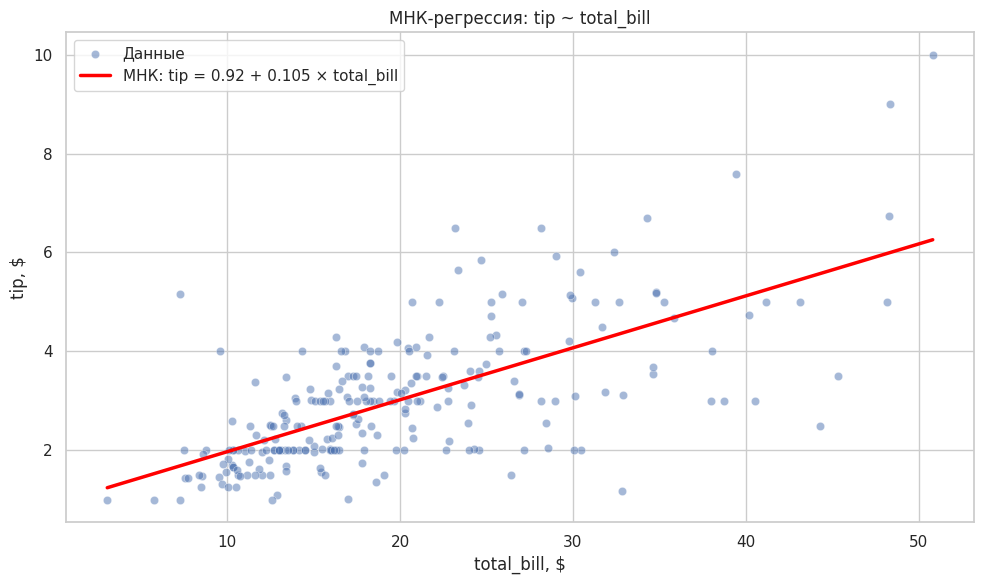

In [ ]:
sns.scatterplot(data=df, x='total_bill', y='tip',
                alpha=0.5, label='Данные')

x_range = np.linspace(df['total_bill'].min(),
                      df['total_bill'].max(), 100)
y_ols = ols.params['Intercept'] + ols.params['total_bill'] * x_range

plt.plot(x_range, y_ols, color='red', linewidth=2.5,
         label=f'МНК: tip = {ols.params["Intercept"]:.2f} + '
               f'{ols.params["total_bill"]:.3f} × total_bill')

plt.title('МНК-регрессия: tip ~ total_bill')
plt.xlabel('total_bill, $')
plt.ylabel('tip, $')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]
mod = smf.quantreg('tip ~ total_bill', data=df)
results = {q: mod.fit(q=q) for q in quantiles}

for q, res in results.items():
    print(f'q={q}: {res.params.to_dict()}')

q=0.1: {'Intercept': 0.8433655889876633, 'total_bill': 0.05102055386558559}
q=0.25: {'Intercept': 0.8202723870220759, 'total_bill': 0.07743257767939028}
q=0.5: {'Intercept': 0.50179938538257, 'total_bill': 0.12410067530534404}
q=0.75: {'Intercept': 0.654096265841809, 'total_bill': 0.14754105913136542}
q=0.9: {'Intercept': 0.6207061347470685, 'total_bill': 0.17654220494933193}


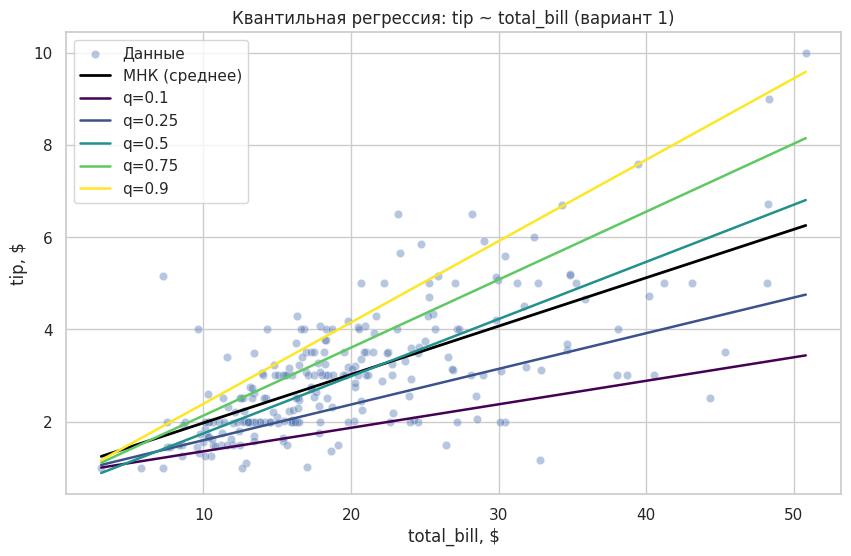

In [ ]:
sns.scatterplot(data=df, x='total_bill', y='tip', alpha=0.4, label='Данные')

x_range = np.linspace(df['total_bill'].min(), df['total_bill'].max(), 100)
y_ols = ols.params['Intercept'] + ols.params['total_bill'] * x_range
plt.plot(x_range, y_ols, color='black', linewidth=2, label='МНК (среднее)')

colors = plt.cm.viridis(np.linspace(0, 1, len(quantiles)))
for (q, res), color in zip(results.items(), colors):
    y_q = res.params['Intercept'] + res.params['total_bill'] * x_range
    plt.plot(x_range, y_q, color=color, linewidth=1.8, label=f'q={q}')

plt.title('Квантильная регрессия: tip ~ total_bill (вариант 1)')
plt.xlabel('total_bill, $')
plt.ylabel('tip, $')
plt.legend()
plt.show()

In [ ]:
rng = np.random.RandomState(1)

X = df[['total_bill']].values
y = df['tip'].values.copy()

n = len(y)
n_outliers = int(0.05 * n)
outlier_idx = rng.choice(n, size=n_outliers, replace=False)

y_out = y.copy()
y_out[outlier_idx] = y_out[outlier_idx] * 4

print(f'Внесено выбросов: {n_outliers}')
print(f'Индексы выбросов: {sorted(outlier_idx)}')
print(f'Пример: было {y[outlier_idx[0]]:.2f}, стало {y_out[outlier_idx[0]]:.2f}')

Внесено выбросов: 12
Индексы выбросов: [np.int64(4), np.int64(58), np.int64(67), np.int64(89), np.int64(122), np.int64(177), np.int64(186), np.int64(206), np.int64(218), np.int64(220), np.int64(226), np.int64(243)]
Пример: было 1.00, стало 4.00


In [ ]:
ols_dirty = LinearRegression().fit(X, y_out)

ols_clean = LinearRegression().fit(X, y)

print('МНК на грязных:  ', ols_dirty.coef_, ols_dirty.intercept_)
print('МНК на чистых:   ', ols_clean.coef_, ols_clean.intercept_)

МНК на грязных:   [0.09503141] 1.4797139705200053
МНК на чистых:    [0.10502452] 0.9202696135546731


In [ ]:
huber = HuberRegressor().fit(X, y_out)

ransac = RANSACRegressor(random_state=1).fit(X, y_out)
inlier_mask = ransac.inlier_mask_

print('Huber:  ', huber.coef_, huber.intercept_)
print('RANSAC: ', ransac.estimator_.coef_, ransac.estimator_.intercept_)
print('Доля наблюдений, признанных RANSAC выбросами:', (~inlier_mask).mean())

Huber:   [0.10464749] 0.9473240857061951
RANSAC:  [0.1390261] 0.33749608898402705
Доля наблюдений, признанных RANSAC выбросами: 0.3155737704918033


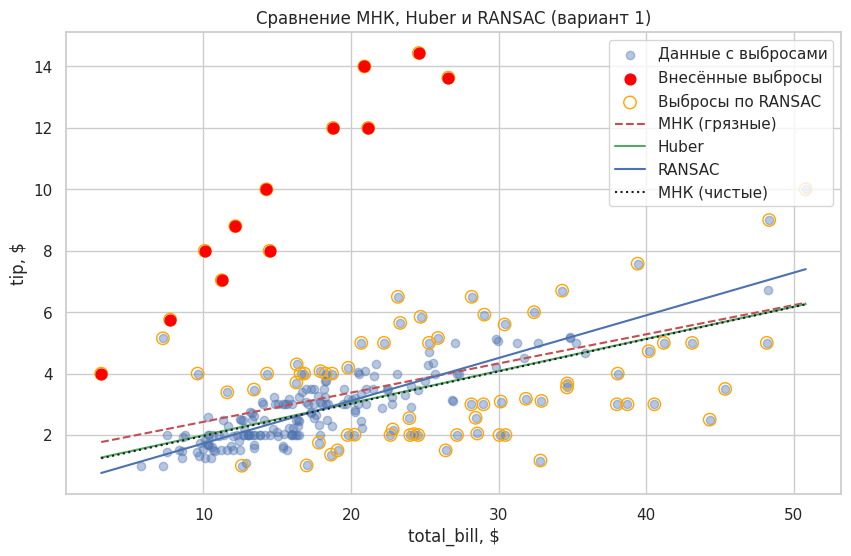

In [ ]:
plt.figure()
plt.scatter(X, y_out, alpha=0.4, label='Данные с выбросами')
plt.scatter(X[outlier_idx], y_out[outlier_idx], color='red', s=60,
            label='Внесённые выбросы', zorder=5)
plt.scatter(X[~inlier_mask], y_out[~inlier_mask], facecolors='none',
            edgecolors='orange', s=80, label='Выбросы по RANSAC', zorder=4)

x_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

def line(model, Xr):
    return model.predict(Xr)

plt.plot(x_range, line(ols_dirty, x_range), 'r--', label='МНК (грязные)')
plt.plot(x_range, line(huber, x_range), 'g-', label='Huber')
plt.plot(x_range, line(ransac, x_range), 'b-', label='RANSAC')
plt.plot(x_range, line(ols_clean, x_range), 'k:', label='МНК (чистые)')

plt.title('Сравнение МНК, Huber и RANSAC (вариант 1)')
plt.xlabel('total_bill, $')
plt.ylabel('tip, $')
plt.legend()
plt.show()

In [ ]:
print('МНК (чистые):  ', ols_clean.coef_, ols_clean.intercept_)
print('МНК (грязные): ', ols_dirty.coef_, ols_dirty.intercept_)
print('Huber:         ', huber.coef_, huber.intercept_)
print('RANSAC:        ', ransac.estimator_.coef_, ransac.estimator_.intercept_)

print(f'RANSAC нашёл выбросов: {(~inlier_mask).sum()} из {n_outliers} внесённых')

МНК (чистые):   [0.10502452] 0.9202696135546731
МНК (грязные):  [0.09503141] 1.4797139705200053
Huber:          [0.10464749] 0.9473240857061951
RANSAC:         [0.1390261] 0.33749608898402705
RANSAC нашёл выбросов: 77 из 12 внесённых
